In [ ]:
'''
= Voting이 유리한 경우
 LogisticRegression, KNN, DecisionTree 등 여러 모델이 서로 다른 장점을 가지고 있을때 
 - 개별 모델의 예측 성능이 괜찮을 때
 - 서로 다른 모델의 예측 오류를 보완하고 싶을 때
 = Bagging이 유리한 경우
 - DecisionTree처럼 데이터 변화에 따라 예측 결과가 크게 달라지는 모델을 사용할 때
 - 과적합을 줄이고 싶을 때
 - 개별 모델의 분산을 줄이고 예측을 안정화하고 싶을 때

 = 금융 분야별 추천 모델
 - 주가 방향 예측	Voting, Boosting	다양한 모델의 예측 결합
 - 신용평가	LogisticRegression, RandomForest	해석력과 비선형 패턴
 - 대출 연체 예측, 금융 사기 탐지, 고객 이탈 예측	RandomForest, Boosting	복잡한 변수 관계 분석, 복잡한 이상 패턴 탐지, 다양한 고객 행동 패턴 분석
 - 기업 부도 예측	Voting, Boosting	여러 모델의 예측력 활용
'''

## Voting Classifier

In [4]:
import warnings

warnings.filterwarnings('ignore')

In [5]:
import pandas as pd

from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 유방암 진단 데이터 셋, 종양의 여러가지 특성을 분석해서 양성인지 악성인지 분류 
cancer = load_breast_cancer()
data_df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
data_df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [6]:
lr_clf = LogisticRegression()
knn_clf = KNeighborsClassifier(n_neighbors=8)

# 개별 모델을 소프트 보팅 기반의 앙상블 모델로 구현한 분류기 
# default : hard voting
vo_clf = VotingClassifier(estimators=[('LR',lr_clf),('KNN',knn_clf)] , voting='soft' )

X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target, 
                                                    test_size=0.2 , random_state= 156)

In [7]:
# VotingClassifier 학습/예측/평가. 
vo_clf.fit(X_train , y_train)
pred = vo_clf.predict(X_test)
print('Voting 분류기 정확도: {0:.4f}'.format(accuracy_score(y_test , pred)))

Voting 분류기 정확도: 0.9474


## Bagging Classifier(Random Forest)

In [8]:
def get_new_feature_name_df(old_feature_name_df):
    feature_dup_df = pd.DataFrame(
        data=old_feature_name_df.groupby("column_name").cumcount(), \
        columns=["dup_cnt"]
    )
    feature_dup_df = feature_dup_df.reset_index()
    new_feature_name_df = pd.merge(
        old_feature_name_df.reset_index(), feature_dup_df, how="outer"
    )
    new_feature_name_df["column_name"] = new_feature_name_df[ ["column_name", "dup_cnt"]].apply(lambda x: x["column_name"] + "_" + str(x["dup_cnt"]) if x["dup_cnt"] > 0 else x["column_name"], axis=1)

    return new_feature_name_df

In [9]:
import pandas as pd

def get_human_dataset():
    feature_name_df = pd.read_csv(
        "./human_activity/features.txt",
        sep="\s+",
        header=None,
        names=["column_index", "column_name"],
    )

    # 신규 피처명 
    new_feature_name_df = get_new_feature_name_df(feature_name_df)

    # DataFrame에 피처명을 컬럼으로 부여하기 위해 리스트 객체로 다시 변환
    feature_name = new_feature_name_df.iloc[:, 1].values.tolist()

    # 학습 피처 데이터 셋과 테스트 피처 데이터을 DataFrame으로 로딩. 
    X_train = pd.read_csv(
        "./human_activity/train/X_train.txt", sep="\s+", names=feature_name
    )
    X_test = pd.read_csv(
        "./human_activity/test/X_test.txt", sep="\s+", names=feature_name
    )

    # 학습 레이블과 테스트 레이블 데이터을 DataFrame으로 로딩하고 
    # 컬럼명은 action으로 부여
    y_train = pd.read_csv(
        "./human_activity/train/y_train.txt", sep="\s+", header=None, 
        names=["action"]
    )
    y_test = pd.read_csv(
        "./human_activity/test/y_test.txt", sep="\s+", header=None,
        names=["action"]
    )

    return X_train, X_test, y_train, y_test

In [10]:
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = get_human_dataset()

rf_clf = RandomForestClassifier(random_state=0)  # estimator 기본개수 : 100
rf_clf.fit(X_train , y_train)
pred = rf_clf.predict(X_test)
accuracy = accuracy_score(y_test , pred)
print('랜덤 포레스트 정확도: {0:.4f}'.format(accuracy))

랜덤 포레스트 정확도: 0.9253


In [11]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators':[100],
    'max_depth' : [6, 8, 10, 12], 
    'min_samples_leaf' : [8, 12, 18 ],
    'min_samples_split' : [8, 16, 20]
}

# n_jobs=-1 : 사용 가능한 CPU 코어를 최대한 활용함 
rf_clf = RandomForestClassifier(random_state=0, n_jobs=-1)
# GridSearchCV의 n_estimators 순위가 RandomForestClassifier의 n_estimators 순위보다 높음
grid_cv = GridSearchCV(rf_clf , param_grid=params , cv=2, n_jobs=-1 )
grid_cv.fit(X_train , y_train)

print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

최적 하이퍼 파라미터:
 {'max_depth': 10, 'min_samples_leaf': 8, 'min_samples_split': 8, 'n_estimators': 100}
최고 예측 정확도: 0.9180


In [12]:
rf_clf1 = RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=8, \
                                min_samples_split=8, random_state=0)
rf_clf1.fit(X_train , y_train)
pred = rf_clf1.predict(X_test)
print('예측 정확도: {0:.4f}'.format(accuracy_score(y_test , pred)))

예측 정확도: 0.9165


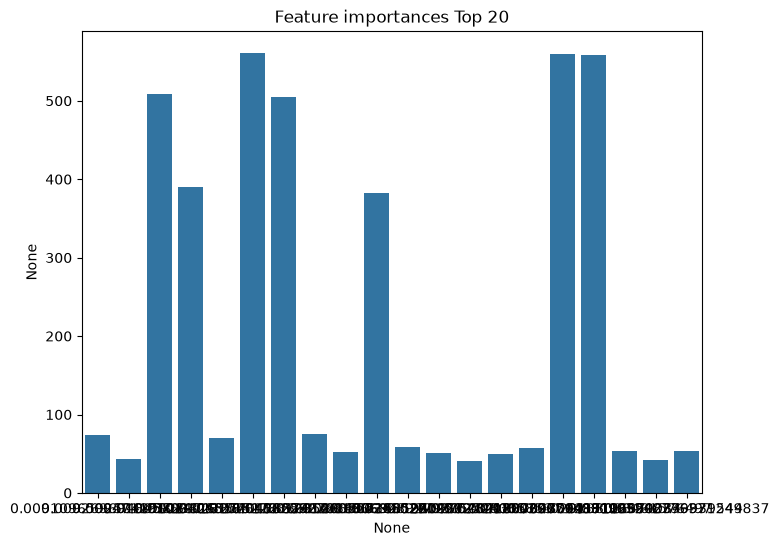

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

ftr_importances_values = rf_clf1.feature_importances_
ftr_importances = pd.Series(ftr_importances_values,index=X_train.columns  )
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]

plt.figure(figsize=(8,6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20 , y = ftr_top20.index)
plt.show()

## GBM(Gradient Boosting Machine)
* 약한 학습기(Weak Learner)를 순차적으로 학습
* 이전 모델이 잘못 예측한 부분을 다음 모델이 보완
* Random Forest는 이전 트리의 오차를 직접 보완하지 않음
  - 여러 트리를 독립적으로 학습
  - 투표, 평균으로 결합을 함 
  - 병렬 학습에 유리
* GBM은 이전 모델의 오차를 보완
  - 트리를 순차적으로 학습
  - 예측 결과를 단계적으로 처리
  - 순차 학습에 유리 
  - AdaBoost : 샘플 가중치 재조정, 주로 분류에서 사용
  - Gradient Boosting : 잔차를 타깃으로 학습을 함, 회귀/분류에서 사용

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
import time
import warnings
warnings.filterwarnings('ignore')

X_train, X_test, y_train, y_test = get_human_dataset()

start_time = time.time()
gb_clf = GradientBoostingClassifier(random_state=0)
gb_clf.fit(X_train , y_train)
gb_pred = gb_clf.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)

print('GBM 정확도: {0:.4f}'.format(gb_accuracy))
print("GBM 수행 시간: {0:.1f} 초 ".format(time.time() - start_time))

In [ ]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators':[100, 500],
    'learning_rate' : [ 0.05, 0.1]
}
grid_cv = GridSearchCV(gb_clf , param_grid=params , cv=2 ,verbose=1)
grid_cv.fit(X_train , y_train)
print('최적 하이퍼 파라미터:\n', grid_cv.best_params_)
print('최고 예측 정확도: {0:.4f}'.format(grid_cv.best_score_))

In [ ]:
gb_pred = grid_cv.best_estimator_.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_pred)
print('GBM 정확도: {0:.4f}'.format(gb_accuracy))